# HW1 Part A - SIR Model Implementation

SIR equations:

- dS/dt = -beta * S * I
- dI/dt = beta * S * I - gamma * I
- dR/dt = gamma * I

I am using the forward Euler method to solve it:

new value = old value + dt * (derivative)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def sir_model(S0, I0, R0, beta, gamma, days, dt=0.1):
    # number of steps
    n = int(days / dt)

    t = np.zeros(n + 1)
    S = np.zeros(n + 1)
    I = np.zeros(n + 1)
    R = np.zeros(n + 1)

    # starting values
    S[0] = S0
    I[0] = I0
    R[0] = R0

    for k in range(n):
        dS = -beta * S[k] * I[k]
        dI = beta * S[k] * I[k] - gamma * I[k]
        dR = gamma * I[k]

        S[k + 1] = S[k] + dt * dS
        I[k + 1] = I[k] + dt * dI
        R[k + 1] = R[k] + dt * dR
        t[k + 1] = t[k] + dt

    return t, S, I, R

### Quick test


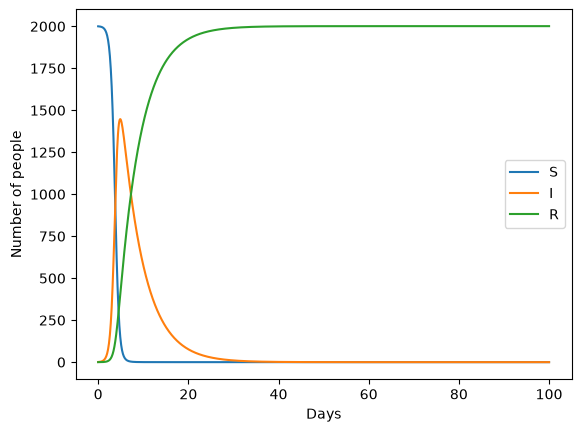

In [6]:
t, S, I, R = sir_model(2000, 1, 0, 0.12e-2, 0.2, 100)

plt.plot(t, S, label='S')
plt.plot(t, I, label='I')
plt.plot(t, R, label='R')
plt.xlabel('Days')
plt.ylabel('Number of people')
plt.legend()
plt.show()

### Checking with a built-in solver

The assignment says we can use a built-in solver only to check. Comparing my Euler result with scipy's odeint.

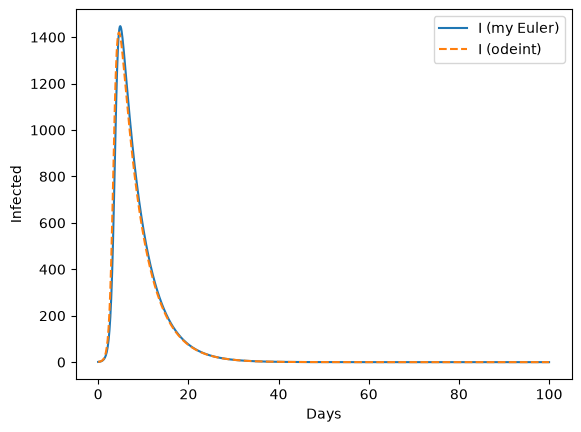

In [8]:
from scipy.integrate import odeint

def sir_deriv(y, t, beta, gamma):
    S, I, R = y
    return [-beta * S * I, beta * S * I - gamma * I, gamma * I]

sol = odeint(sir_deriv, [2000, 1, 0], t, args=(0.12e-2, 0.2))

plt.plot(t, I, label='I (my Euler)')
plt.plot(t, sol[:, 1], '--', label='I (odeint)')
plt.xlabel('Days')
plt.ylabel('Infected')
plt.legend()
plt.show()